TIMEGPT + METEOROLOGÍA + CORRECCIÓN DEL CABLE
Archivo             : unificada.csv
Inicio predicción   : 2026-02-15 00:00:00
Horizonte           : 168 horas
Pasos               : 672
Contexto TimeGPT    : 630 días
Frecuencia          : 15min
Ventana cable       : +/- 20 días

Exógenas meteorológicas:
 - temperatura
 - humedad
 - presion
 - precipitacion
 - veloc_de_viento_prom_10m

Cargando datos...
Dimensión original: (336767, 19)

Todas las columnas necesarias fueron encontradas.

Timestamps duplicados: 3

Registros después de regularizar: 350102

Faltantes originales:
radiacion                   13642
temperatura                 13467
humedad                     13443
presion                     15103
precipitacion               13381
veloc_de_viento_prom_10m    13342
dtype: int64

Faltantes finales:
radiacion                   0
temperatura                 0
humedad                     0
presion                     0
precipitacion               0
veloc_de_viento_prom_10m    0
dtype:

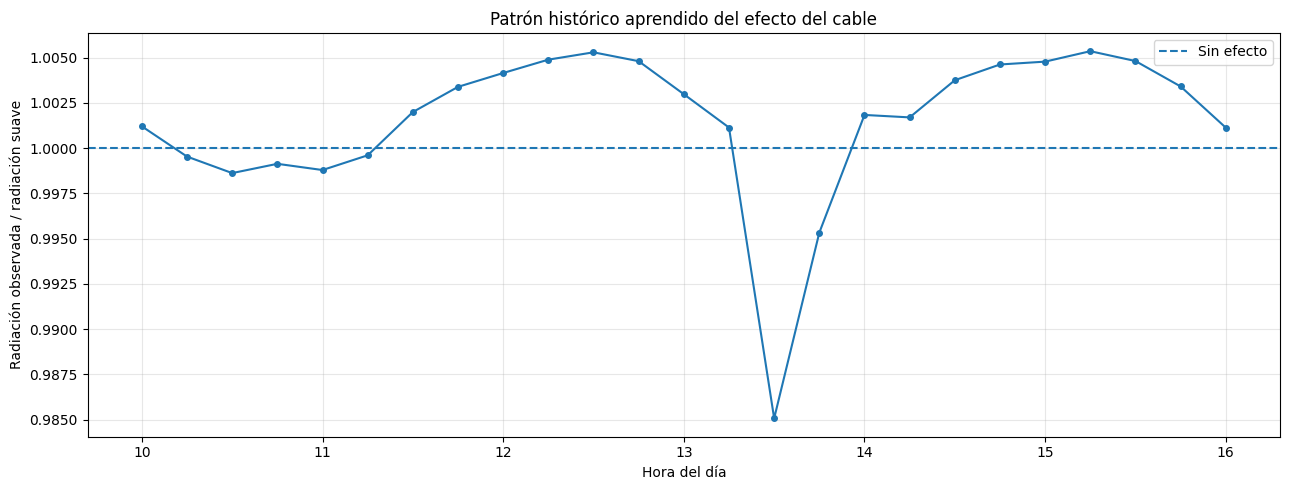

INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing dataframes...



Train: 60480
Test : 672

Variables enviadas a TimeGPT:
 - temperatura
 - humedad
 - presion
 - precipitacion
 - veloc_de_viento_prom_10m
 - hora_sin
 - hora_cos
 - anio_sin
 - anio_cos

Frecuencia detectada: 15T

EJECUTANDO TIMEGPT


INFO:nixtla.nixtla_client:Querying model metadata...
INFO:nixtla.nixtla_client:Using future exogenous features: ['temperatura', 'humedad', 'presion', 'precipitacion', 'veloc_de_viento_prom_10m', 'hora_sin', 'hora_cos', 'anio_sin', 'anio_cos']
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...



TimeGPT terminado.

Columnas devueltas: ['unique_id', 'ds', 'TimeGPT', 'TimeGPT-hi-80', 'TimeGPT-lo-80']

COMPARACIÓN DE RESULTADOS
                    Modelo   MAE_24h  RMSE_24h      WAPE  MAE_diurno  RMSE_diurno  MAE_zona_cable  RMSE_zona_cable
                   TimeGPT 50.929066 98.581862 25.851556    98.95528   140.632522      111.107246       150.490275
TimeGPT + corrección cable 51.063965 98.720511 25.920031    99.23166   140.831645      111.625260       150.838885


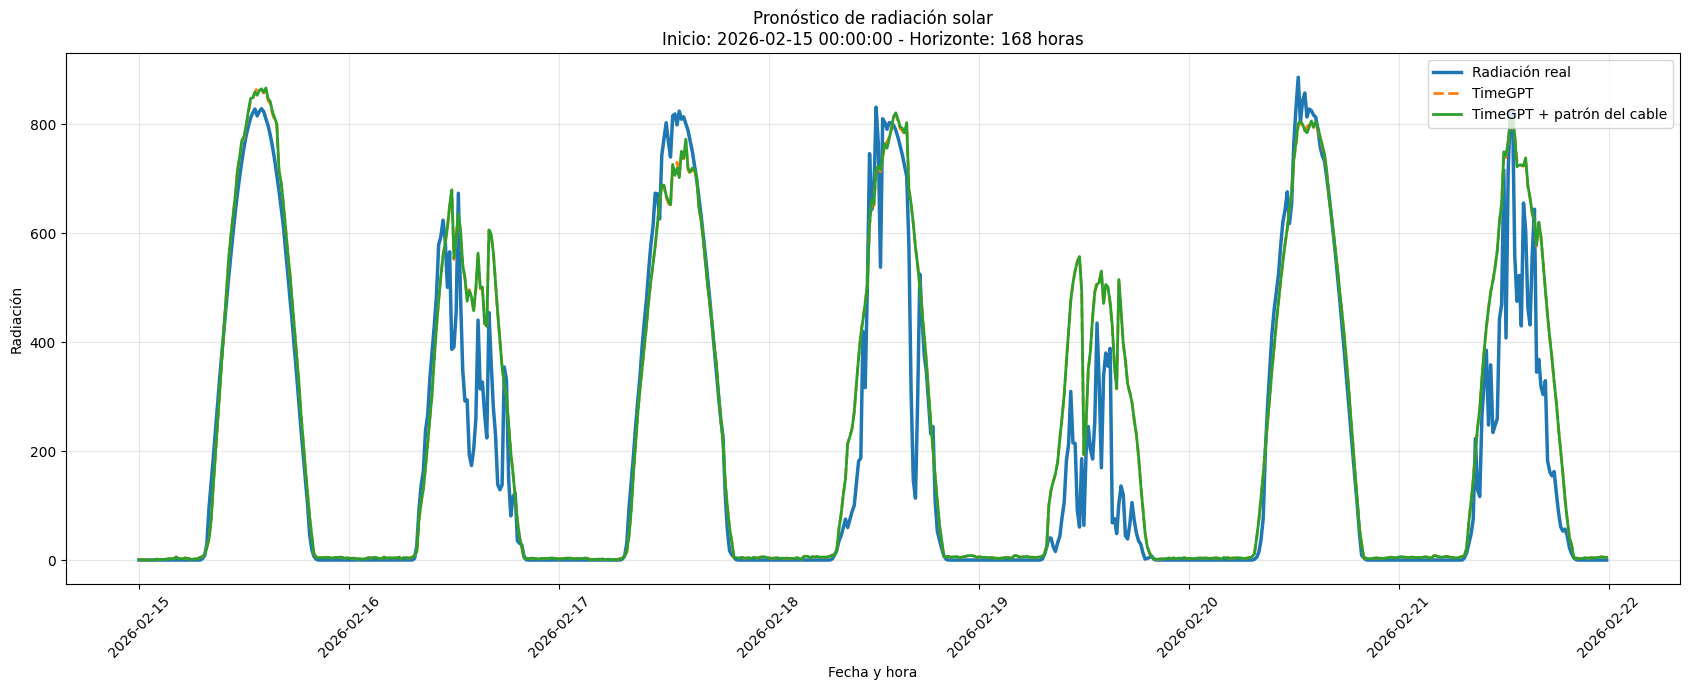

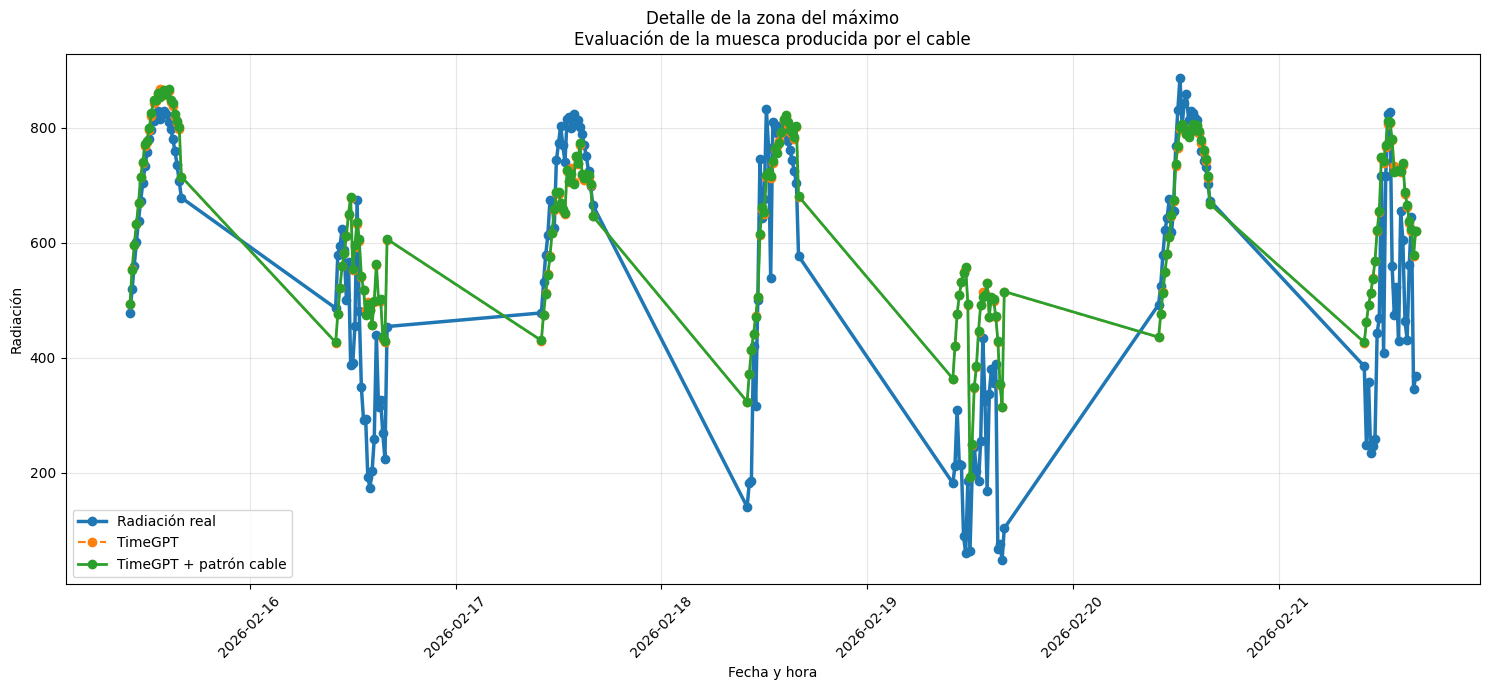

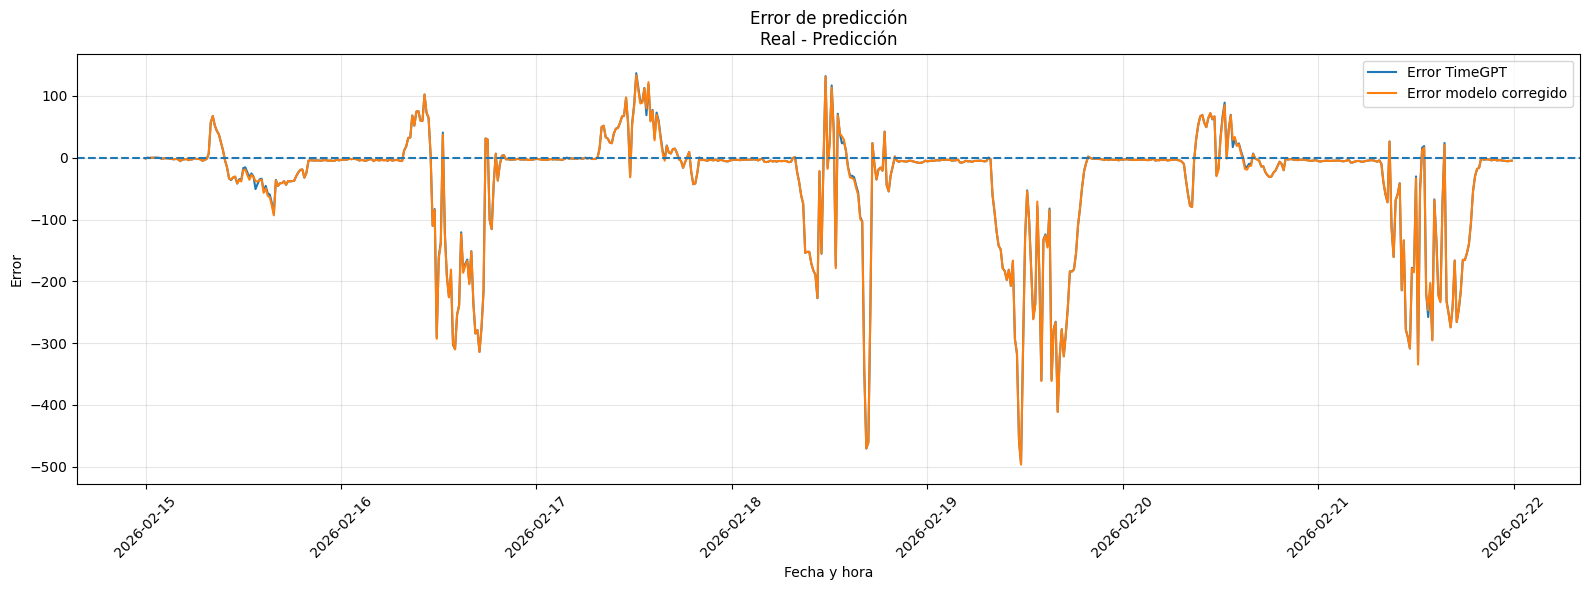


PROCESO TERMINADO
Resultados guardados en: resultado_timegpt_cable_2026-02-15_168h


In [1]:
# ============================================================
# TIMEGPT + VARIABLES METEOROLÓGICAS
# + CORRECCIÓN HISTÓRICA DEL EFECTO DEL CABLE
#
# Objetivo: pronóstico de radiación solar cada 15 minutos
# ============================================================


# ============================================================
# 0. LIBRERÍAS
# ============================================================

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import savgol_filter

from nixtla import NixtlaClient

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================
#
# MODIFICAR PRINCIPALMENTE ESTA SECCIÓN
# ============================================================

ARCHIVO = "unificada.csv"

FECHA = "fecha"
TARGET = "radiacion"


# ------------------------------------------------------------
# PERÍODO DE PREDICCIÓN
# ------------------------------------------------------------

# Fecha y hora donde comienza el pronóstico
FECHA_INICIO_TEST = "2026-02-15 00:00:00"

# Horizonte de predicción
HORAS_PREDICCION = 168

# Historia reciente entregada a TimeGPT
DIAS_CONTEXTO = 630


# ------------------------------------------------------------
# FRECUENCIA
# ------------------------------------------------------------

FREQ = "15min"

PASOS_POR_HORA = 4

H = HORAS_PREDICCION * PASOS_POR_HORA


# ------------------------------------------------------------
# VARIABLES EXÓGENAS
# ------------------------------------------------------------

EXOGENAS_METEO = [
    "temperatura",
    "humedad",
    "presion",
    "precipitacion",
    "veloc_de_viento_prom_10m"
]


# ------------------------------------------------------------
# CONFIGURACIÓN DEL EFECTO DEL CABLE
# ------------------------------------------------------------
#
# Solo corregiremos la región central del día.
# Podés ampliar/reducir estas horas posteriormente.
# ------------------------------------------------------------

HORA_CABLE_INICIO = 10
HORA_CABLE_FIN = 16


# Días alrededor de la fecha del test que se utilizarán
# históricamente para aprender el patrón.
#
# Ejemplo:
# 15 de marzo +/- 20 días de TODOS los años anteriores.
#
VENTANA_DIAS_ANIO = 20


# Ventana Savitzky-Golay.
#
# Debe ser impar.
#
# 21 puntos x 15 min = 5 h 15 min
#
VENTANA_SUAVIZADO = 21

ORDEN_POLINOMIO = 3


# ============================================================
# 2. MOSTRAR CONFIGURACIÓN
# ============================================================

print("=" * 75)
print("TIMEGPT + METEOROLOGÍA + CORRECCIÓN DEL CABLE")
print("=" * 75)

print(f"Archivo             : {ARCHIVO}")
print(f"Inicio predicción   : {FECHA_INICIO_TEST}")
print(f"Horizonte           : {HORAS_PREDICCION} horas")
print(f"Pasos               : {H}")
print(f"Contexto TimeGPT    : {DIAS_CONTEXTO} días")
print(f"Frecuencia          : {FREQ}")
print(f"Ventana cable       : +/- {VENTANA_DIAS_ANIO} días")

print("\nExógenas meteorológicas:")

for variable in EXOGENAS_METEO:
    print(" -", variable)


# ============================================================
# 3. CONECTAR CON TIMEGPT
# ============================================================
#
# Antes de ejecutar:
#
# export NIXTLA_API_KEY="tu_api_key"
#
# o configurarla en el entorno de Jupyter.
# ============================================================

#API_KEY = os.getenv("NIXTLA_API_KEY")

API_KEY = 'nixak-0dea77cc906e018c018d8bd6071c8c6cfb754654bb3adb5585155dbbcd7ba352cbcbefd609d95044'

if not API_KEY:

    raise ValueError(
        "\nNo se encontró NIXTLA_API_KEY.\n"
        "Configurá tu API Key de Nixtla antes de continuar."
    )


nixtla_client = NixtlaClient(
    api_key=API_KEY
)


# ============================================================
# 4. CARGAR CSV
# ============================================================

print("\nCargando datos...")


df = pd.read_csv(
    ARCHIVO,
    sep=";",
    low_memory=False
)


print(
    "Dimensión original:",
    df.shape
)


# ============================================================
# 5. COMPROBAR COLUMNAS
# ============================================================

COLUMNAS_NECESARIAS = (
    [FECHA, TARGET]
    +
    EXOGENAS_METEO
)


faltantes = [
    c
    for c in COLUMNAS_NECESARIAS
    if c not in df.columns
]


if faltantes:

    print("\nColumnas disponibles:")

    for c in df.columns:
        print(" -", c)

    raise ValueError(
        f"\nFaltan estas columnas: {faltantes}"
    )


print("\nTodas las columnas necesarias fueron encontradas.")


# ============================================================
# 6. CONVERTIR FECHA
# ============================================================

df[FECHA] = pd.to_datetime(
    df[FECHA],
    dayfirst=True,
    errors="coerce"
)


df = df.dropna(
    subset=[FECHA]
)


# ============================================================
# 7. CONVERTIR VARIABLES A NUMÉRICO
# ============================================================

VARIABLES = [
    TARGET
] + EXOGENAS_METEO


for columna in VARIABLES:

    df[columna] = pd.to_numeric(
        df[columna],
        errors="coerce"
    )


df = df[
    [FECHA] + VARIABLES
].copy()


# ============================================================
# 8. ORDENAR Y ELIMINAR DUPLICADOS
# ============================================================

print(
    "\nTimestamps duplicados:",
    df[FECHA].duplicated().sum()
)


df = (
    df
    .groupby(
        FECHA,
        as_index=False
    )[VARIABLES]
    .mean()
)


df = df.sort_values(
    FECHA
)


# ============================================================
# 9. CREAR GRILLA EXACTA DE 15 MINUTOS
# ============================================================

df = df.set_index(
    FECHA
)


indice_completo = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq=FREQ
)


df = df.reindex(
    indice_completo
)


df.index.name = FECHA


print(
    "\nRegistros después de regularizar:",
    len(df)
)


print("\nFaltantes originales:")

print(
    df[VARIABLES]
    .isna()
    .sum()
)


# ============================================================
# 10. INTERPOLACIÓN
# ============================================================
#
# Primero huecos pequeños.
# ============================================================

for columna in VARIABLES:

    df[columna] = (
        df[columna]
        .interpolate(
            method="time",
            limit=4
        )
    )


# Para que TimeGPT no falle por timestamps faltantes,
# completamos los restantes.
#
# ATENCIÓN:
# esto debe documentarse en el informe.
# ============================================================

for columna in VARIABLES:

    df[columna] = (
        df[columna]
        .interpolate(
            method="time",
            limit_direction="both"
        )
    )


print("\nFaltantes finales:")

print(
    df[VARIABLES]
    .isna()
    .sum()
)


df = df.reset_index()


# ============================================================
# 11. VARIABLES TEMPORALES
# ============================================================

df["hora_decimal"] = (
    df[FECHA].dt.hour
    +
    df[FECHA].dt.minute / 60
)


df["hora"] = (
    df[FECHA].dt.hour
)


df["minuto"] = (
    df[FECHA].dt.minute
)


df["dia_anio"] = (
    df[FECHA].dt.dayofyear
)


df["dia"] = (
    df[FECHA].dt.date
)


# ============================================================
# 12. VARIABLES TEMPORALES CÍCLICAS
# ============================================================

df["hora_sin"] = np.sin(
    2 * np.pi
    * df["hora_decimal"]
    / 24
)


df["hora_cos"] = np.cos(
    2 * np.pi
    * df["hora_decimal"]
    / 24
)


df["anio_sin"] = np.sin(
    2 * np.pi
    * df["dia_anio"]
    / 365.25
)


df["anio_cos"] = np.cos(
    2 * np.pi
    * df["dia_anio"]
    / 365.25
)


TEMPORALES = [
    "hora_sin",
    "hora_cos",
    "anio_sin",
    "anio_cos"
]


# ============================================================
# 13. DEFINIR PERÍODO DE PREDICCIÓN
# ============================================================

fecha_inicio = pd.Timestamp(
    FECHA_INICIO_TEST
)


fecha_fin = (
    fecha_inicio
    +
    pd.Timedelta(
        minutes=15 * (H - 1)
    )
)


fecha_contexto = (
    fecha_inicio
    -
    pd.Timedelta(
        days=DIAS_CONTEXTO
    )
)


print("\n" + "=" * 75)
print("PERÍODO DEL EXPERIMENTO")
print("=" * 75)

print(
    "Contexto desde  :",
    fecha_contexto
)

print(
    "Predicción desde:",
    fecha_inicio
)

print(
    "Predicción hasta:",
    fecha_fin
)


# ============================================================
# 14. COMPROBAR QUE EL TEST EXISTE
# ============================================================

test = df[
    (df[FECHA] >= fecha_inicio)
    &
    (df[FECHA] <= fecha_fin)
].copy()


if len(test) != H:

    raise ValueError(
        f"\nEl período solicitado debería tener {H} registros "
        f"pero se encontraron {len(test)}.\n"
        "Revisá FECHA_INICIO_TEST y HORAS_PREDICCION."
    )


# ============================================================
# 15. HISTÓRICO PARA APRENDER EL EFECTO DEL CABLE
# ============================================================
#
# MUY IMPORTANTE:
#
# solamente utilizamos información ANTERIOR a la fecha
# que queremos pronosticar.
# ============================================================

historico = df[
    df[FECHA] < fecha_inicio
].copy()


print(
    "\nObservaciones históricas disponibles:",
    len(historico)
)


# ============================================================
# 16. CREAR CURVA SUAVE PARA CADA DÍA
# ============================================================
#
# El objetivo es separar:
#
# curva solar general
#
# de
#
# pequeñas deformaciones locales repetitivas.
# ============================================================


def suavizar_dia(grupo):

    grupo = grupo.sort_values(
        FECHA
    ).copy()

    valores = grupo[
        TARGET
    ].to_numpy(
        dtype=float
    )

    n = len(valores)

    if n >= VENTANA_SUAVIZADO:

        ventana = VENTANA_SUAVIZADO

        # asegurar ventana impar

        if ventana % 2 == 0:
            ventana += 1

        if ventana > n:

            ventana = (
                n
                if n % 2 == 1
                else n - 1
            )

        if ventana > ORDEN_POLINOMIO:

            suave = savgol_filter(
                valores,
                window_length=ventana,
                polyorder=ORDEN_POLINOMIO,
                mode="interp"
            )

        else:

            suave = valores.copy()

    else:

        suave = valores.copy()


    grupo[
        "radiacion_suave"
    ] = suave


    return grupo


print("\nCalculando perfiles diarios...")


historico = (

    historico

    .groupby(
        "dia",
        group_keys=False
    )

    .apply(
        suavizar_dia
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 17. CALCULAR FACTOR HISTÓRICO
# ============================================================
#
# factor = radiación observada / curva suave
#
# factor = 1
#     sin modificación
#
# factor < 1
#     depresión respecto de la curva suave
#
# ============================================================

historico[
    "factor_cable"
] = np.where(

    historico[
        "radiacion_suave"
    ] > 100,

    historico[TARGET]
    /
    historico[
        "radiacion_suave"
    ],

    1.0

)


historico[
    "factor_cable"
] = (

    historico[
        "factor_cable"
    ]

    .replace(
        [np.inf, -np.inf],
        np.nan
    )

)


# ============================================================
# 18. EVITAR QUE NUBES EXTREMAS DOMINEN EL PERFIL
# ============================================================

historico[
    "factor_cable"
] = (

    historico[
        "factor_cable"
    ]

    .clip(
        lower=0.75,
        upper=1.15
    )

)


# ============================================================
# 19. SELECCIONAR FECHAS SIMILARES DEL AÑO
# ============================================================

dia_test = (
    fecha_inicio.dayofyear
)


historico[
    "distancia_dia"
] = np.abs(
    historico["dia_anio"]
    -
    dia_test
)


# distancia circular:
# diciembre y enero también pueden ser cercanos

historico[
    "distancia_dia"
] = np.minimum(

    historico[
        "distancia_dia"
    ],

    365
    -
    historico[
        "distancia_dia"
    ]

)


hist_cercano = historico[

    historico[
        "distancia_dia"
    ]
    <=
    VENTANA_DIAS_ANIO

].copy()


print(
    "\nObservaciones usadas para aprender patrón:",
    len(hist_cercano)
)


# ============================================================
# 20. QUEDARNOS CON HORAS CENTRALES
# ============================================================

hist_cable = hist_cercano[

    (
        hist_cercano[
            "hora_decimal"
        ]
        >=
        HORA_CABLE_INICIO
    )

    &

    (
        hist_cercano[
            "hora_decimal"
        ]
        <=
        HORA_CABLE_FIN
    )

    &

    (
        hist_cercano[
            "radiacion_suave"
        ]
        > 100
    )

].copy()


# ============================================================
# 21. PERFIL DEL CABLE
# ============================================================
#
# NO buscamos anomalías.
#
# Calculamos directamente la MEDIANA del factor para cada
# intervalo de 15 minutos.
#
# Si el cable produce siempre la misma pequeña caída,
# debería sobrevivir al promedio/mediana histórica.
# ============================================================

perfil_cable = (

    hist_cable

    .groupby(
        [
            "hora",
            "minuto"
        ],
        as_index=False
    )

    .agg(

        factor_cable=(
            "factor_cable",
            "median"
        ),

        numero_observaciones=(
            "factor_cable",
            "count"
        )

    )

)


# ============================================================
# 22. ASEGURAR QUE EL FACTOR EXISTA
# ============================================================

if perfil_cable.empty:

    print(
        "\nADVERTENCIA:"
        " no se pudo aprender el perfil del cable."
    )

    perfil_cable = pd.DataFrame({
        "hora": [],
        "minuto": [],
        "factor_cable": [],
        "numero_observaciones": []
    })


print("\nPerfil histórico del cable:")

print(
    perfil_cable.to_string(
        index=False
    )
)


# ============================================================
# 23. GRÁFICO DEL PATRÓN APRENDIDO
# ============================================================

if not perfil_cable.empty:

    perfil_cable[
        "hora_decimal"
    ] = (

        perfil_cable["hora"]

        +

        perfil_cable["minuto"]
        / 60

    )


    plt.figure(
        figsize=(13, 5)
    )


    plt.plot(
        perfil_cable[
            "hora_decimal"
        ],
        perfil_cable[
            "factor_cable"
        ],
        marker="o",
        markersize=4
    )


    plt.axhline(
        1,
        linestyle="--",
        label="Sin efecto"
    )


    plt.title(
        "Patrón histórico aprendido del efecto del cable"
    )


    plt.xlabel(
        "Hora del día"
    )


    plt.ylabel(
        "Radiación observada / radiación suave"
    )


    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 24. INCORPORAR FACTOR HISTÓRICO A TODA LA BASE
# ============================================================

# Por seguridad eliminar columnas de ejecuciones anteriores

for columna in [
    "factor_cable",
    "numero_observaciones"
]:

    if columna in df.columns:

        df = df.drop(
            columns=columna
        )


df = df.merge(

    perfil_cable[
        [
            "hora",
            "minuto",
            "factor_cable"
        ]
    ],

    on=[
        "hora",
        "minuto"
    ],

    how="left"

)


# ============================================================
# 25. FUERA DE LA ZONA DEL CABLE = FACTOR 1
# ============================================================

df[
    "factor_cable"
] = (

    df[
        "factor_cable"
    ]

    .fillna(1.0)

)


# ============================================================
# 26. TRAIN Y TEST
# ============================================================

train = df[

    (df[FECHA] >= fecha_contexto)

    &

    (df[FECHA] < fecha_inicio)

].copy()


test = df[

    (df[FECHA] >= fecha_inicio)

    &

    (df[FECHA] <= fecha_fin)

].copy()


print("\nTrain:", len(train))
print("Test :", len(test))


# ============================================================
# 27. VARIABLES EXÓGENAS FINALES
# ============================================================

EXOGENAS_MODELO = (

    EXOGENAS_METEO

    +

    TEMPORALES

)


print("\nVariables enviadas a TimeGPT:")

for variable in EXOGENAS_MODELO:
    print(" -", variable)


# ============================================================
# 28. PREPARAR TRAIN PARA TIMEGPT
# ============================================================

train_tg = train.rename(
    columns={
        FECHA: "ds",
        TARGET: "y"
    }
)


train_tg[
    "unique_id"
] = "radiacion"


train_tg = train_tg[

    [
        "unique_id",
        "ds",
        "y"
    ]

    +

    EXOGENAS_MODELO

].copy()


# ============================================================
# 29. PREPARAR VARIABLES FUTURAS
# ============================================================
#
# En esta evaluación retrospectiva conocemos temperatura,
# humedad, presión, precipitación y viento del período test.
#
# Para un pronóstico futuro real estas variables deberían
# provenir de un pronóstico meteorológico.
# ============================================================

X_df = test.rename(
    columns={
        FECHA: "ds"
    }
)


X_df[
    "unique_id"
] = "radiacion"


X_df = X_df[

    [
        "unique_id",
        "ds"
    ]

    +

    EXOGENAS_MODELO

].copy()


# ============================================================
# 30. VERIFICACIONES
# ============================================================

if train_tg.isna().sum().sum() > 0:

    print(
        train_tg.isna().sum()
    )

    raise ValueError(
        "Existen NaN en TRAIN."
    )


if X_df.isna().sum().sum() > 0:

    print(
        X_df.isna().sum()
    )

    raise ValueError(
        "Existen NaN en X_df."
    )


print(
    "\nFrecuencia detectada:",
    pd.infer_freq(
        train_tg["ds"]
    )
)


# ============================================================
# 31. EJECUTAR TIMEGPT
# ============================================================

print("\n" + "=" * 75)
print("EJECUTANDO TIMEGPT")
print("=" * 75)


forecast = nixtla_client.forecast(

    df=train_tg,

    X_df=X_df,

    h=H,

    freq=FREQ,

    time_col="ds",

    target_col="y",

    id_col="unique_id",

    level=[80]

)


print("\nTimeGPT terminado.")


# ============================================================
# 32. IDENTIFICAR COLUMNA DE PREDICCIÓN
# ============================================================

print(
    "\nColumnas devueltas:",
    forecast.columns.tolist()
)


if "TimeGPT" in forecast.columns:

    pred_col = "TimeGPT"

else:

    posibles = [

        c
        for c in forecast.columns

        if c not in [
            "unique_id",
            "ds"
        ]

        and "lo-" not in c.lower()

        and "hi-" not in c.lower()

    ]

    if not posibles:

        raise ValueError(
            "No se encontró la columna de predicción."
        )

    pred_col = posibles[0]


# ============================================================
# 33. CREAR RESULTADO
# ============================================================

forecast[
    "ds"
] = pd.to_datetime(
    forecast["ds"]
)


real = test[
    [
        FECHA,
        TARGET,
        "factor_cable"
    ]
].copy()


real = real.rename(
    columns={
        FECHA: "ds",
        TARGET: "real"
    }
)


resultado = real.merge(
    forecast,
    on="ds",
    how="left"
)


resultado = resultado.rename(
    columns={
        pred_col:
        "prediccion_timegpt"
    }
)


# ============================================================
# 34. CORRECCIÓN DEL CABLE
# ============================================================
#
# TimeGPT predice la curva general.
#
# El factor histórico introduce la pequeña deformación
# sistemática observada por el sensor.
# ============================================================

resultado[
    "prediccion_corregida"
] = (

    resultado[
        "prediccion_timegpt"
    ]

    *

    resultado[
        "factor_cable"
    ]

)


# ============================================================
# 35. EVITAR RADIACIÓN NEGATIVA
# ============================================================

resultado[
    "prediccion_timegpt"
] = (

    resultado[
        "prediccion_timegpt"
    ]

    .clip(
        lower=0
    )

)


resultado[
    "prediccion_corregida"
] = (

    resultado[
        "prediccion_corregida"
    ]

    .clip(
        lower=0
    )

)


# ============================================================
# 36. ERRORES
# ============================================================

resultado[
    "error_timegpt"
] = (

    resultado["real"]

    -

    resultado[
        "prediccion_timegpt"
    ]

)


resultado[
    "error_corregido"
] = (

    resultado["real"]

    -

    resultado[
        "prediccion_corregida"
    ]

)


# ============================================================
# 37. FUNCIÓN DE MÉTRICAS
# ============================================================

def calcular_metricas(
    real,
    pred
):

    real = np.asarray(
        real,
        dtype=float
    )

    pred = np.asarray(
        pred,
        dtype=float
    )


    mae = mean_absolute_error(
        real,
        pred
    )


    rmse = np.sqrt(
        mean_squared_error(
            real,
            pred
        )
    )


    if np.sum(
        np.abs(real)
    ) > 0:

        wape = (

            100

            *

            np.sum(
                np.abs(
                    real - pred
                )
            )

            /

            np.sum(
                np.abs(real)
            )

        )

    else:

        wape = np.nan


    return (
        mae,
        rmse,
        wape
    )


# ============================================================
# 38. MÉTRICAS GENERALES
# ============================================================

MAE_TG, RMSE_TG, WAPE_TG = calcular_metricas(

    resultado["real"],

    resultado[
        "prediccion_timegpt"
    ]

)


MAE_CORR, RMSE_CORR, WAPE_CORR = calcular_metricas(

    resultado["real"],

    resultado[
        "prediccion_corregida"
    ]

)


# ============================================================
# 39. MÉTRICAS DIURNAS
# ============================================================

mask_dia = (
    resultado["real"]
    >
    20
)


MAE_TG_DIA, RMSE_TG_DIA, _ = calcular_metricas(

    resultado.loc[
        mask_dia,
        "real"
    ],

    resultado.loc[
        mask_dia,
        "prediccion_timegpt"
    ]

)


MAE_CORR_DIA, RMSE_CORR_DIA, _ = calcular_metricas(

    resultado.loc[
        mask_dia,
        "real"
    ],

    resultado.loc[
        mask_dia,
        "prediccion_corregida"
    ]

)


# ============================================================
# 40. MÉTRICAS ESPECÍFICAS DE LA ZONA DEL CABLE
# ============================================================

resultado[
    "hora_decimal"
] = (

    resultado[
        "ds"
    ].dt.hour

    +

    resultado[
        "ds"
    ].dt.minute
    / 60

)


mask_cable = (

    resultado[
        "hora_decimal"
    ]
    >=
    HORA_CABLE_INICIO

) & (

    resultado[
        "hora_decimal"
    ]
    <=
    HORA_CABLE_FIN

)


MAE_TG_CABLE, RMSE_TG_CABLE, _ = calcular_metricas(

    resultado.loc[
        mask_cable,
        "real"
    ],

    resultado.loc[
        mask_cable,
        "prediccion_timegpt"
    ]

)


MAE_CORR_CABLE, RMSE_CORR_CABLE, _ = calcular_metricas(

    resultado.loc[
        mask_cable,
        "real"
    ],

    resultado.loc[
        mask_cable,
        "prediccion_corregida"
    ]

)


# ============================================================
# 41. TABLA DE RESULTADOS
# ============================================================

metricas = pd.DataFrame({

    "Modelo": [
        "TimeGPT",
        "TimeGPT + corrección cable"
    ],

    "MAE_24h": [
        MAE_TG,
        MAE_CORR
    ],

    "RMSE_24h": [
        RMSE_TG,
        RMSE_CORR
    ],

    "WAPE": [
        WAPE_TG,
        WAPE_CORR
    ],

    "MAE_diurno": [
        MAE_TG_DIA,
        MAE_CORR_DIA
    ],

    "RMSE_diurno": [
        RMSE_TG_DIA,
        RMSE_CORR_DIA
    ],

    "MAE_zona_cable": [
        MAE_TG_CABLE,
        MAE_CORR_CABLE
    ],

    "RMSE_zona_cable": [
        RMSE_TG_CABLE,
        RMSE_CORR_CABLE
    ]

})


print("\n" + "=" * 75)
print("COMPARACIÓN DE RESULTADOS")
print("=" * 75)

print(
    metricas.to_string(
        index=False
    )
)


# ============================================================
# 42. GRÁFICO COMPLETO
# ============================================================

plt.figure(
    figsize=(17, 7)
)


plt.plot(
    resultado["ds"],
    resultado["real"],
    linewidth=2.5,
    label="Radiación real"
)


plt.plot(
    resultado["ds"],
    resultado[
        "prediccion_timegpt"
    ],
    "--",
    linewidth=2,
    label="TimeGPT"
)


plt.plot(
    resultado["ds"],
    resultado[
        "prediccion_corregida"
    ],
    linewidth=2,
    label="TimeGPT + patrón del cable"
)


plt.title(
    "Pronóstico de radiación solar\n"
    f"Inicio: {FECHA_INICIO_TEST} - "
    f"Horizonte: {HORAS_PREDICCION} horas"
)


plt.xlabel(
    "Fecha y hora"
)


plt.ylabel(
    "Radiación"
)


plt.legend()

plt.grid(
    alpha=0.3
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


# ============================================================
# 43. ZOOM DE LA ZONA DEL CABLE
# ============================================================

zoom = resultado[
    mask_cable
].copy()


plt.figure(
    figsize=(15, 7)
)


plt.plot(
    zoom["ds"],
    zoom["real"],
    marker="o",
    linewidth=2.5,
    label="Radiación real"
)


plt.plot(
    zoom["ds"],
    zoom[
        "prediccion_timegpt"
    ],
    "--",
    marker="o",
    label="TimeGPT"
)


plt.plot(
    zoom["ds"],
    zoom[
        "prediccion_corregida"
    ],
    marker="o",
    linewidth=2,
    label="TimeGPT + patrón cable"
)


plt.title(
    "Detalle de la zona del máximo\n"
    "Evaluación de la muesca producida por el cable"
)


plt.xlabel(
    "Fecha y hora"
)


plt.ylabel(
    "Radiación"
)


plt.legend()

plt.grid(
    alpha=0.3
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


# ============================================================
# 44. GRÁFICO DEL ERROR
# ============================================================

plt.figure(
    figsize=(16, 6)
)


plt.plot(
    resultado["ds"],
    resultado[
        "error_timegpt"
    ],
    label="Error TimeGPT"
)


plt.plot(
    resultado["ds"],
    resultado[
        "error_corregido"
    ],
    label="Error modelo corregido"
)


plt.axhline(
    0,
    linestyle="--"
)


plt.title(
    "Error de predicción\n"
    "Real - Predicción"
)


plt.xlabel(
    "Fecha y hora"
)


plt.ylabel(
    "Error"
)


plt.legend()

plt.grid(
    alpha=0.3
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


# ============================================================
# 45. GUARDAR RESULTADOS
# ============================================================

nombre_fecha = (
    fecha_inicio
    .strftime(
        "%Y-%m-%d"
    )
)


CARPETA_RESULTADOS = (

    f"resultado_timegpt_cable_"
    f"{nombre_fecha}_"
    f"{HORAS_PREDICCION}h"

)


os.makedirs(
    CARPETA_RESULTADOS,
    exist_ok=True
)


resultado.to_csv(

    os.path.join(
        CARPETA_RESULTADOS,
        "pronostico_completo.csv"
    ),

    index=False

)


metricas.to_csv(

    os.path.join(
        CARPETA_RESULTADOS,
        "metricas.csv"
    ),

    index=False

)


perfil_cable.to_csv(

    os.path.join(
        CARPETA_RESULTADOS,
        "perfil_historico_cable.csv"
    ),

    index=False

)


print("\n" + "=" * 75)
print("PROCESO TERMINADO")
print("=" * 75)

print(
    "Resultados guardados en:",
    CARPETA_RESULTADOS
)

GUARDANDO RESULTADOS

Carpeta:
resultados_timegpt_cable_2026-02-15_168h

Predicciones guardadas: resultados_timegpt_cable_2026-02-15_168h/predicciones.csv
Métricas guardadas: resultados_timegpt_cable_2026-02-15_168h/metricas.csv
Perfil del cable guardado: resultados_timegpt_cable_2026-02-15_168h/perfil_historico_cable.csv
Configuración guardada: resultados_timegpt_cable_2026-02-15_168h/configuracion.txt


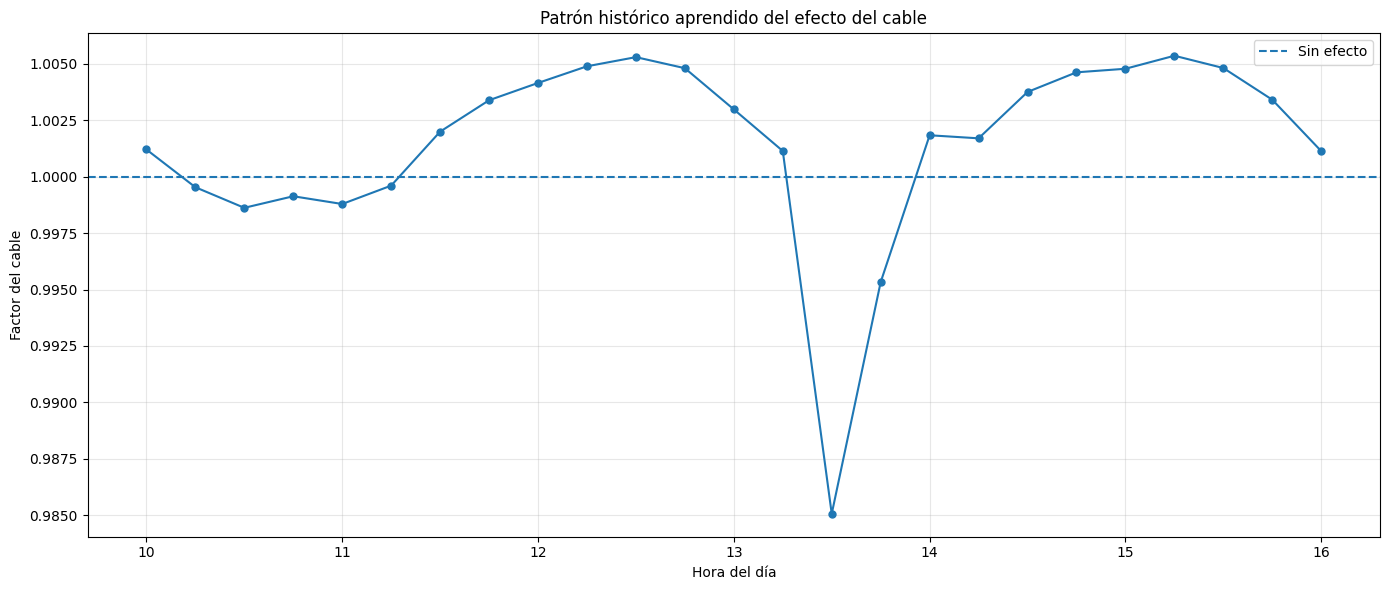

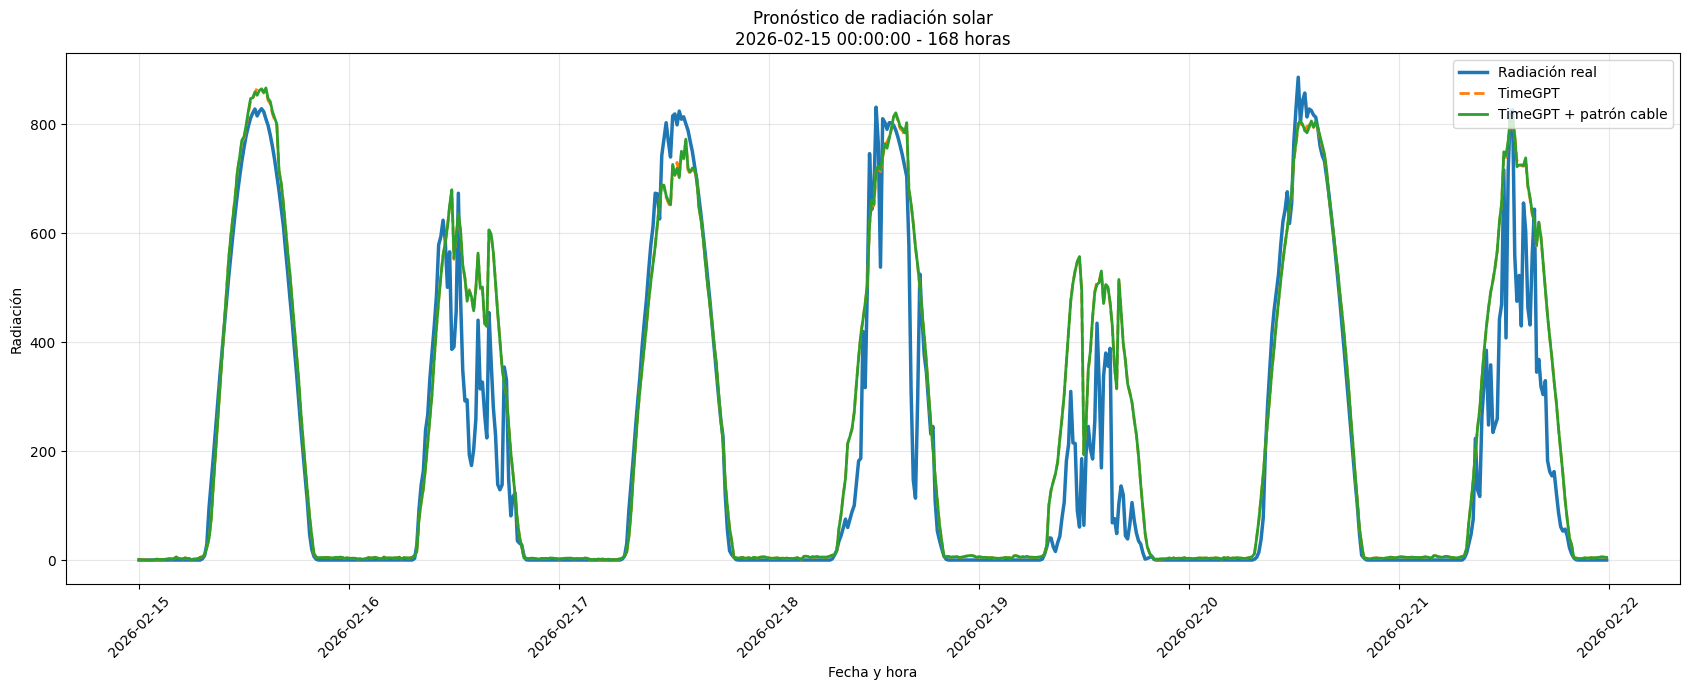

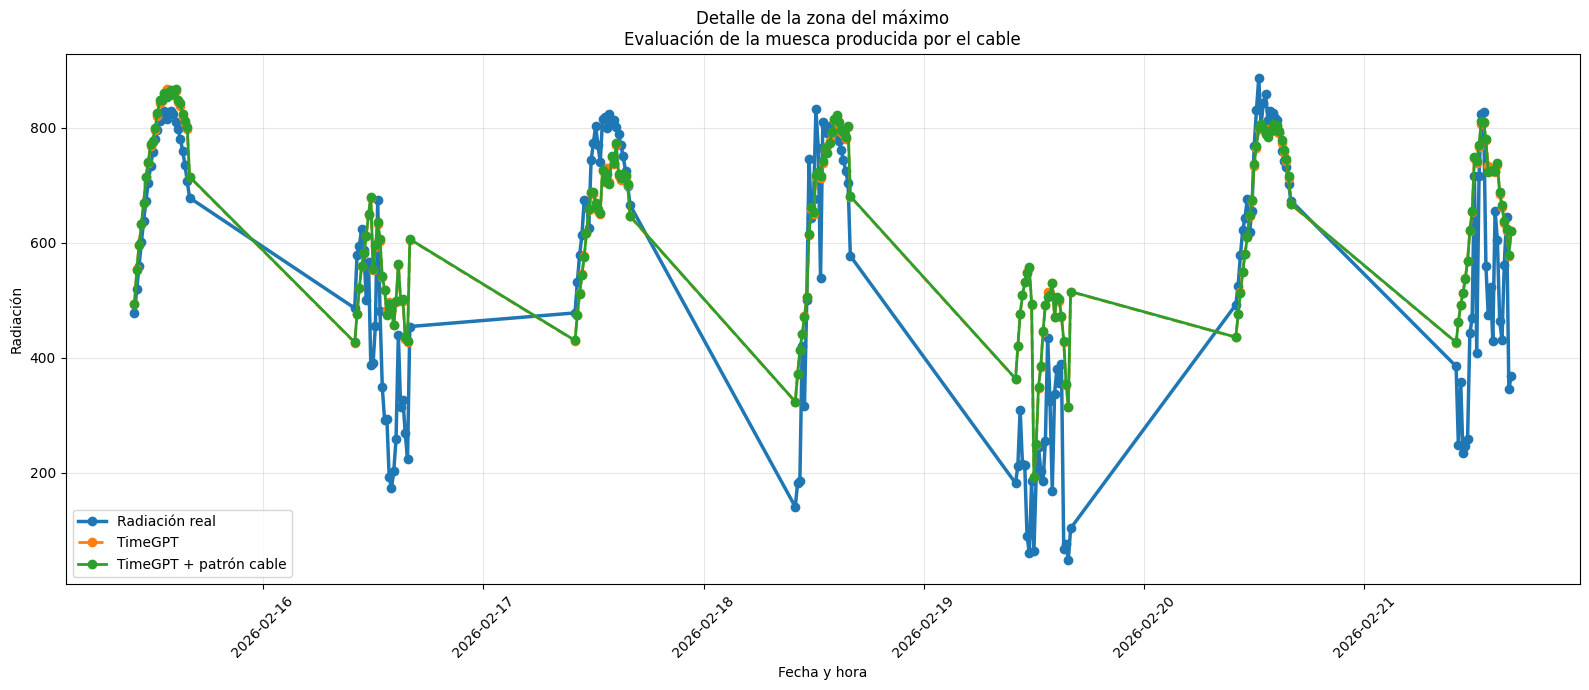

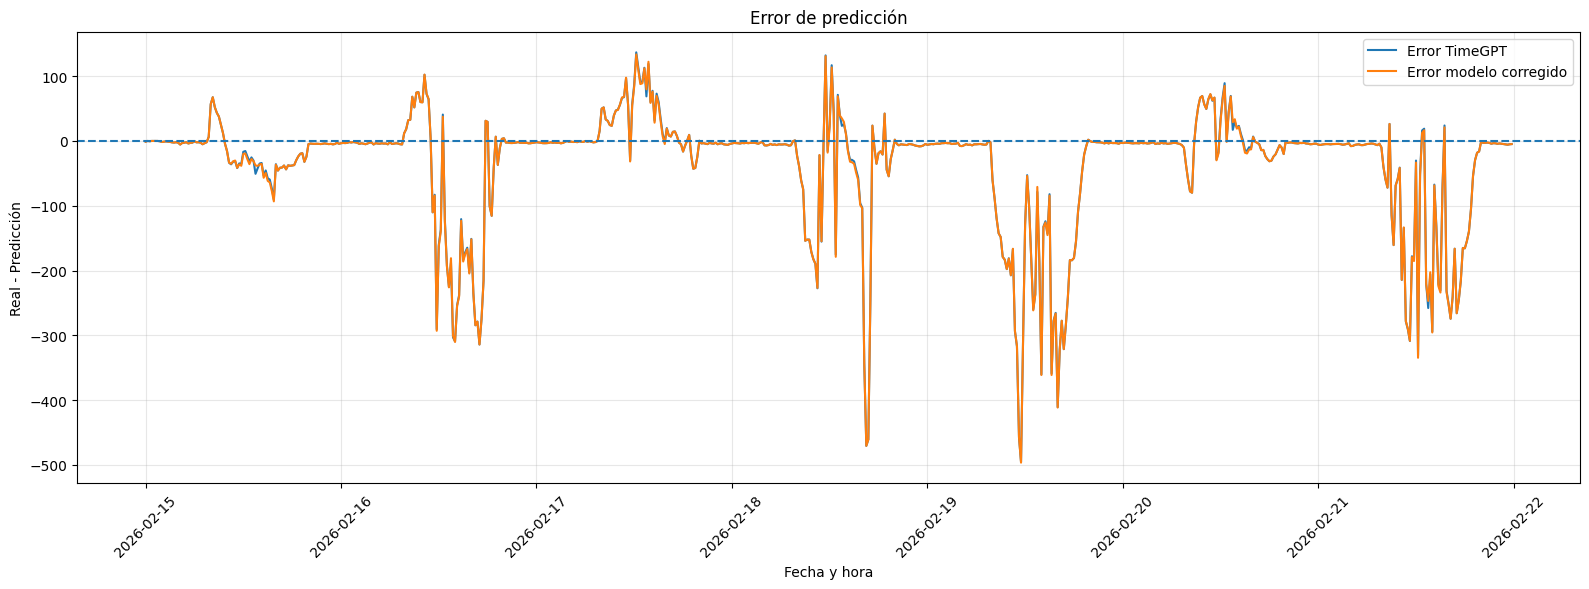



TODOS LOS RESULTADOS FUERON GUARDADOS

Carpeta: resultados_timegpt_cable_2026-02-15_168h

Archivos generados:
 - 01_patron_historico_cable.png
 - 02_pronostico_completo.png
 - 03_detalle_muesca_cable.png
 - 04_error_prediccion.png
 - configuracion.txt
 - metricas.csv
 - metricas.txt
 - perfil_historico_cable.csv
 - predicciones.csv
 - todos_los_graficos.pdf


In [2]:
# ============================================================
# GUARDAR TODOS LOS RESULTADOS DEL EXPERIMENTO
# ============================================================

import os
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages


# ============================================================
# 1. CREAR CARPETA DEL EXPERIMENTO
# ============================================================

fecha_nombre = pd.Timestamp(
    FECHA_INICIO_TEST
).strftime("%Y-%m-%d")


CARPETA_SALIDA = (
    f"resultados_timegpt_cable_"
    f"{fecha_nombre}_"
    f"{HORAS_PREDICCION}h"
)


os.makedirs(
    CARPETA_SALIDA,
    exist_ok=True
)


print("=" * 70)
print("GUARDANDO RESULTADOS")
print("=" * 70)

print("\nCarpeta:")
print(CARPETA_SALIDA)


# ============================================================
# 2. GUARDAR PREDICCIONES COMPLETAS
# ============================================================

archivo_predicciones = os.path.join(
    CARPETA_SALIDA,
    "predicciones.csv"
)


resultado.to_csv(
    archivo_predicciones,
    index=False
)


print(
    "\nPredicciones guardadas:",
    archivo_predicciones
)


# ============================================================
# 3. GUARDAR MÉTRICAS
# ============================================================

archivo_metricas = os.path.join(
    CARPETA_SALIDA,
    "metricas.csv"
)


metricas.to_csv(
    archivo_metricas,
    index=False
)


print(
    "Métricas guardadas:",
    archivo_metricas
)


# ============================================================
# 4. GUARDAR PERFIL HISTÓRICO DEL CABLE
# ============================================================

archivo_perfil = os.path.join(
    CARPETA_SALIDA,
    "perfil_historico_cable.csv"
)


perfil_cable.to_csv(
    archivo_perfil,
    index=False
)


print(
    "Perfil del cable guardado:",
    archivo_perfil
)


# ============================================================
# 5. GUARDAR CONFIGURACIÓN DEL EXPERIMENTO
# ============================================================

archivo_configuracion = os.path.join(
    CARPETA_SALIDA,
    "configuracion.txt"
)


with open(
    archivo_configuracion,
    "w",
    encoding="utf-8"
) as archivo:

    archivo.write(
        "EXPERIMENTO TIMEGPT + CORRECCIÓN DEL CABLE\n"
    )

    archivo.write(
        "=" * 60 + "\n\n"
    )

    archivo.write(
        f"Archivo de datos: {ARCHIVO}\n"
    )

    archivo.write(
        f"Fecha inicio test: {FECHA_INICIO_TEST}\n"
    )

    archivo.write(
        f"Horizonte: {HORAS_PREDICCION} horas\n"
    )

    archivo.write(
        f"Pasos de predicción: {H}\n"
    )

    archivo.write(
        f"Frecuencia: {FREQ}\n"
    )

    archivo.write(
        f"Días de contexto: {DIAS_CONTEXTO}\n"
    )

    archivo.write(
        f"Ventana histórica: +/- {VENTANA_DIAS_ANIO} días\n"
    )

    archivo.write(
        f"Zona cable: {HORA_CABLE_INICIO}:00 "
        f"a {HORA_CABLE_FIN}:00\n"
    )

    archivo.write(
        "\nVariables exógenas:\n"
    )

    for variable in EXOGENAS_METEO:
        archivo.write(
            f"- {variable}\n"
        )


print(
    "Configuración guardada:",
    archivo_configuracion
)


# ============================================================
# 6. GUARDAR TABLA DE MÉTRICAS TAMBIÉN COMO TXT
# ============================================================

archivo_metricas_txt = os.path.join(
    CARPETA_SALIDA,
    "metricas.txt"
)


with open(
    archivo_metricas_txt,
    "w",
    encoding="utf-8"
) as archivo:

    archivo.write(
        "MÉTRICAS DEL EXPERIMENTO\n"
    )

    archivo.write(
        "=" * 80 + "\n\n"
    )

    archivo.write(
        metricas.to_string(
            index=False
        )
    )


# ============================================================
# 7. CREAR GRÁFICOS NUEVAMENTE Y GUARDARLOS
# ============================================================
#
# Esto es más seguro que intentar recuperar figuras
# que ya fueron mostradas con plt.show().
# ============================================================


# ============================================================
# GRÁFICO 1
# PATRÓN HISTÓRICO DEL CABLE
# ============================================================

if not perfil_cable.empty:

    perfil_plot = perfil_cable.copy()

    perfil_plot[
        "hora_decimal"
    ] = (
        perfil_plot["hora"]
        +
        perfil_plot["minuto"] / 60
    )


    fig1 = plt.figure(
        figsize=(14, 6)
    )


    plt.plot(
        perfil_plot["hora_decimal"],
        perfil_plot["factor_cable"],
        marker="o",
        markersize=5
    )


    plt.axhline(
        y=1,
        linestyle="--",
        label="Sin efecto"
    )


    plt.title(
        "Patrón histórico aprendido del efecto del cable"
    )

    plt.xlabel(
        "Hora del día"
    )

    plt.ylabel(
        "Factor del cable"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()


    fig1.savefig(
        os.path.join(
            CARPETA_SALIDA,
            "01_patron_historico_cable.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )


# ============================================================
# GRÁFICO 2
# PRONÓSTICO COMPLETO
# ============================================================

fig2 = plt.figure(
    figsize=(17, 7)
)


plt.plot(
    resultado["ds"],
    resultado["real"],
    linewidth=2.5,
    label="Radiación real"
)


plt.plot(
    resultado["ds"],
    resultado["prediccion_timegpt"],
    "--",
    linewidth=2,
    label="TimeGPT"
)


plt.plot(
    resultado["ds"],
    resultado["prediccion_corregida"],
    linewidth=2,
    label="TimeGPT + patrón cable"
)


plt.title(
    "Pronóstico de radiación solar\n"
    f"{FECHA_INICIO_TEST} - "
    f"{HORAS_PREDICCION} horas"
)


plt.xlabel(
    "Fecha y hora"
)

plt.ylabel(
    "Radiación"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.xticks(
    rotation=45
)

plt.tight_layout()


fig2.savefig(
    os.path.join(
        CARPETA_SALIDA,
        "02_pronostico_completo.png"
    ),
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# GRÁFICO 3
# ZOOM DE LA MUESCA
# ============================================================

zoom = resultado[
    mask_cable
].copy()


fig3 = plt.figure(
    figsize=(16, 7)
)


plt.plot(
    zoom["ds"],
    zoom["real"],
    marker="o",
    linewidth=2.5,
    label="Radiación real"
)


plt.plot(
    zoom["ds"],
    zoom["prediccion_timegpt"],
    "--",
    marker="o",
    linewidth=2,
    label="TimeGPT"
)


plt.plot(
    zoom["ds"],
    zoom["prediccion_corregida"],
    marker="o",
    linewidth=2,
    label="TimeGPT + patrón cable"
)


plt.title(
    "Detalle de la zona del máximo\n"
    "Evaluación de la muesca producida por el cable"
)


plt.xlabel(
    "Fecha y hora"
)

plt.ylabel(
    "Radiación"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.xticks(
    rotation=45
)

plt.tight_layout()


fig3.savefig(
    os.path.join(
        CARPETA_SALIDA,
        "03_detalle_muesca_cable.png"
    ),
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# GRÁFICO 4
# ERROR
# ============================================================

fig4 = plt.figure(
    figsize=(16, 6)
)


plt.plot(
    resultado["ds"],
    resultado["error_timegpt"],
    label="Error TimeGPT"
)


plt.plot(
    resultado["ds"],
    resultado["error_corregido"],
    label="Error modelo corregido"
)


plt.axhline(
    y=0,
    linestyle="--"
)


plt.title(
    "Error de predicción"
)


plt.xlabel(
    "Fecha y hora"
)

plt.ylabel(
    "Real - Predicción"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.xticks(
    rotation=45
)

plt.tight_layout()


fig4.savefig(
    os.path.join(
        CARPETA_SALIDA,
        "04_error_prediccion.png"
    ),
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# 8. GUARDAR TODOS LOS GRÁFICOS EN UN SOLO PDF
# ============================================================

archivo_pdf = os.path.join(
    CARPETA_SALIDA,
    "todos_los_graficos.pdf"
)


with PdfPages(
    archivo_pdf
) as pdf:

    if not perfil_cable.empty:
        pdf.savefig(
            fig1,
            bbox_inches="tight"
        )

    pdf.savefig(
        fig2,
        bbox_inches="tight"
    )

    pdf.savefig(
        fig3,
        bbox_inches="tight"
    )

    pdf.savefig(
        fig4,
        bbox_inches="tight"
    )


# ============================================================
# 9. MOSTRAR LOS GRÁFICOS
# ============================================================

plt.show()


# ============================================================
# 10. RESUMEN FINAL
# ============================================================

print("\n")
print("=" * 70)
print("TODOS LOS RESULTADOS FUERON GUARDADOS")
print("=" * 70)

print(
    "\nCarpeta:",
    CARPETA_SALIDA
)

print("\nArchivos generados:")

for archivo in sorted(
    os.listdir(
        CARPETA_SALIDA
    )
):

    print(
        " -",
        archivo
    )